# **MÓDULO 17 - Projeto de Credit Score - Parte 1 - Processamento dos dados**


Essa é a primeira etapa do processo de Credit Score que vocês desenvolverão durante nosso curso.
Nessa primeira etapa vocês irão aplicar os passos aprendidos nos módulos de pré processamento para preparar a base de vocês para o desenvolvimento do modelo.

O termo "credit score" se refere a uma pontuação numérica que representa a credibilidade de um indivíduo em termos de cumprimento de obrigações financeiras, como pagar contas de empréstimos, cartões de crédito, entre outros. Essa pontuação é calculada com base em diversas informações financeiras e de crédito do indivíduo, como histórico de pagamentos, níveis de endividamento, tempo de crédito, tipos de crédito utilizados, entre outros.

O objetivo de um modelo de credit score é prever o risco de um indivíduo se tornar inadimplente com suas obrigações financeiras. Em outras palavras, o modelo avalia a probabilidade de um indivíduo não cumprir com os pagamentos de empréstimos ou outros compromissos financeiros. Essa previsão é fundamental para instituições financeiras, como bancos e credores, na tomada de decisão sobre a concessão de crédito. Um modelo de credit score eficaz pode ajudar essas instituições a avaliar o risco de emprestar dinheiro a um determinado indivíduo e, assim, tomar decisões mais informadas sobre a aprovação ou negação de crédito, bem como sobre os termos e condições desses empréstimos.

**Atenção:** Notem que esse projeto é diferente da base que tenho trabalhado com vocês em aula, apesar de se tratar de uma base bancária durante a aula falamos sobre a variável Churn a ser prevista, nesse caso a previsão seria do valor do Score de Crédito.

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import numpy as np
import sklearn
from sklearn.preprocessing import LabelEncoder

In [3]:
#Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("../data/raw/credit_score.csv", delimiter=';')

df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,"50.000,00",Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,"100.000,00",Master's Degree,Married,2,Owned,High
2,35.0,Female,"75.000,00",Doctorate,Married,1,Owned,High
3,40.0,Male,"125.000,00",High School Diploma,Single,0,Owned,High
4,45.0,Female,"100.000,00",Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,"150.000,00",Master's Degree,Married,0,Owned,High
6,26.0,Female,"40.000,00",Associate's Degree,Single,0,Rented,Average
7,31.0,Male,"60.000,00",Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,"80.000,00",Master's Degree,Married,2,Owned,High
9,NaN,Male,"105.000,00",Doctorate,Single,0,Owned,High


Legenda dos dados:

*   **Age** : Idade dos nossos clientes.

*   **Income** : Salário Mensal.

*   **Gender** : Gênero.

*   **Education** : Nível de escolaridade dos clientes.

*   **Marital** : Status Civilmente.

*   **Number of Children** : Quantidade de filhos.

*   **Home** : Tipo de residência, alugada ou própria.

*   **Credit Score** : Nossa variável preditora, o score de crédito dos clientes.


# Etapa 1: Relize os passos que vimos no módulo 18, de pré processamento dos dados.

**A) Verifique os tipos de dados, fazendo as transformações quando necessário.**


In [4]:
#A) seu código aqui
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 130 non-null    float64
 1   Gender              164 non-null    str    
 2   Income              164 non-null    str    
 3   Education           164 non-null    str    
 4   Marital Status      164 non-null    str    
 5   Number of Children  164 non-null    int64  
 6   Home Ownership      164 non-null    str    
 7   Credit Score        164 non-null    str    
dtypes: float64(1), int64(1), str(6)
memory usage: 10.4 KB


In [5]:
# Convertendo 'Income' e 'Number of Children' para 'float'

df['Income'] = df['Income'].str.replace('.','')
df['Income'] = df['Income'].str.replace(',','')
df['Income'] = df['Income'].astype(float)
df['Number of Children'] = pd.to_numeric(df['Number of Children'], errors = 'coerce')
df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,5000000.0,Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,10000000.0,Master's Degree,Married,2,Owned,High
2,35.0,Female,7500000.0,Doctorate,Married,1,Owned,High
3,40.0,Male,12500000.0,High School Diploma,Single,0,Owned,High
4,45.0,Female,10000000.0,Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,15000000.0,Master's Degree,Married,0,Owned,High
6,26.0,Female,4000000.0,Associate's Degree,Single,0,Rented,Average
7,31.0,Male,6000000.0,Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,8000000.0,Master's Degree,Married,2,Owned,High
9,NaN,Male,10500000.0,Doctorate,Single,0,Owned,High


In [6]:
df['Income'] = df['Income']/100
df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,50000.0,Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,100000.0,Master's Degree,Married,2,Owned,High
2,35.0,Female,75000.0,Doctorate,Married,1,Owned,High
3,40.0,Male,125000.0,High School Diploma,Single,0,Owned,High
4,45.0,Female,100000.0,Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,150000.0,Master's Degree,Married,0,Owned,High
6,26.0,Female,40000.0,Associate's Degree,Single,0,Rented,Average
7,31.0,Male,60000.0,Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,80000.0,Master's Degree,Married,2,Owned,High
9,NaN,Male,105000.0,Doctorate,Single,0,Owned,High


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 130 non-null    float64
 1   Gender              164 non-null    str    
 2   Income              164 non-null    float64
 3   Education           164 non-null    str    
 4   Marital Status      164 non-null    str    
 5   Number of Children  164 non-null    int64  
 6   Home Ownership      164 non-null    str    
 7   Credit Score        164 non-null    str    
dtypes: float64(2), int64(1), str(5)
memory usage: 10.4 KB


**B) Verifique se temos colunas com dados faltantes.
Caso existam colunas com dados faltantes faça o tratamento desses dados, excluindo ou substituindo esses valores. Justifique sua escolha.**

In [8]:
#seu código aqui
df.isnull().sum()

Age                   34
Gender                 0
Income                 0
Education              0
Marital Status         0
Number of Children     0
Home Ownership         0
Credit Score           0
dtype: int64

In [9]:
(df.isnull().sum() / len(df)) * 100

Age                   20.731707
Gender                 0.000000
Income                 0.000000
Education              0.000000
Marital Status         0.000000
Number of Children     0.000000
Home Ownership         0.000000
Credit Score           0.000000
dtype: float64

**C) Verifique se temos valores digitados de forma incorreta nas variáveis categóricas que necessitem de tratamento.**

In [10]:
#seu código aqui
print(df['Gender'].unique())
print(df['Education'].unique())
print(df['Marital Status'].unique())
print(df['Home Ownership'].unique())

<StringArray>
['Female', 'Male']
Length: 2, dtype: str
<StringArray>
[  'Bachelor's Degree',     'Master's Degree',           'Doctorate',
 'High School Diploma',  'Associate's Degree']
Length: 5, dtype: str
<StringArray>
['Single', 'Married']
Length: 2, dtype: str
<StringArray>
['Rented', 'Owned']
Length: 2, dtype: str


Aparentemente, tudo 'ok'

# Etapa 2: Relize os passos que vimos no módulo 15, de análise.

**A) Realiza a análise univariada, aplique a função describe ao nosso dataframe para verificar os dados das variáveis numéricas, se encontrar a possível presença de outliers analise com gráficos a distribuição dos dados.Traga insights sobre os dados analisados.**

In [11]:
#seu código aqui
df.describe()

,Age,Income,Number of Children
count,130.000000,164.000000,164.000000
mean,37.507692,83765.243902,0.652439
std,8.500110,32457.306728,0.883346
min,25.000000,25000.000000,0.000000
25%,30.000000,57500.000000,0.000000
50%,36.000000,83750.000000,0.000000
75%,45.000000,105000.000000,1.000000
max,53.000000,162500.000000,3.000000


**B) Agora realize a análise univariada para as variaveis categóricas, plote gráficos para entender a distribuição das categorias e tente retirar insights de cada gráfico.**

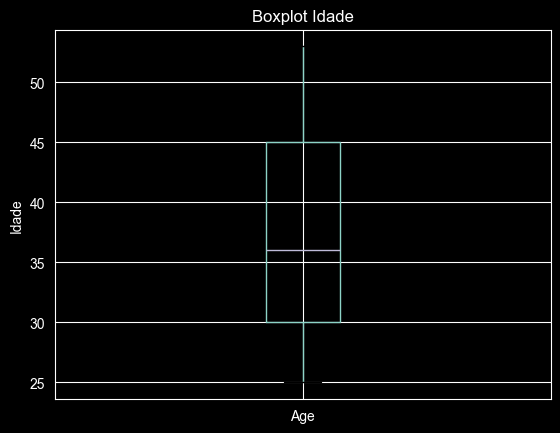

In [12]:
#seu código aqui
df.boxplot(column='Age')
plt.title('Boxplot Idade')
plt.ylabel('Idade')
plt.show()

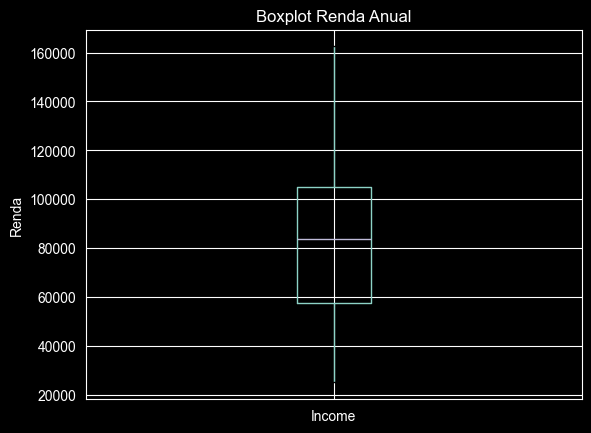

In [13]:
df.boxplot(column='Income')
plt.title('Boxplot Renda Anual')
plt.ylabel('Renda')
plt.show()

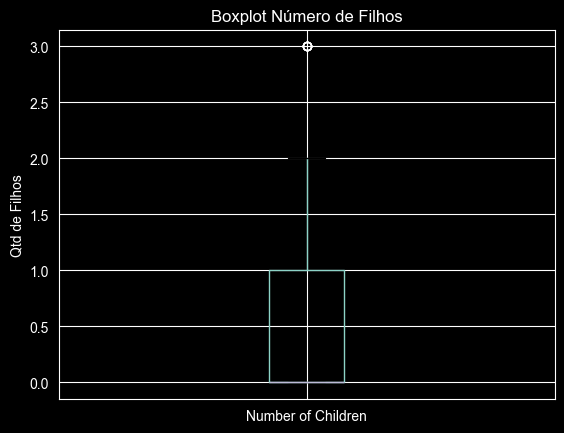

In [14]:
df.boxplot(column='Number of Children')
plt.title('Boxplot Número de Filhos')
plt.ylabel('Qtd de Filhos')
plt.show()

**C) Você encontrou alguma coluna com outliers?
Se sim realize o tratamento desses casos.**

**SIM**. A coluna 'Number of Children' possui um outlier

In [15]:
#seu código aqui
outlier_filhos = df[df['Number of Children'] == 3]
print(outlier_filhos)

      Age  Gender    Income          Education Marital Status  \
4    45.0  Female  100000.0  Bachelor's Degree        Married   
33   45.0  Female  105000.0  Bachelor's Degree        Married   
65   45.0  Female  110000.0  Bachelor's Degree        Married   
97   45.0  Female  115000.0  Bachelor's Degree        Married   
139  45.0  Female  105000.0  Bachelor's Degree        Married   

     Number of Children Home Ownership Credit Score  
4                     3          Owned         High  
33                    3          Owned         High  
65                    3          Owned         High  
97                    3          Owned         High  
139                   3          Owned         High  


In [16]:
len(outlier_filhos)

5

Temos apenas 5 dados de outlier. Será removido para melhorar a análise

In [17]:
df.drop(df[df['Number of Children'] == 3].index, inplace = True)

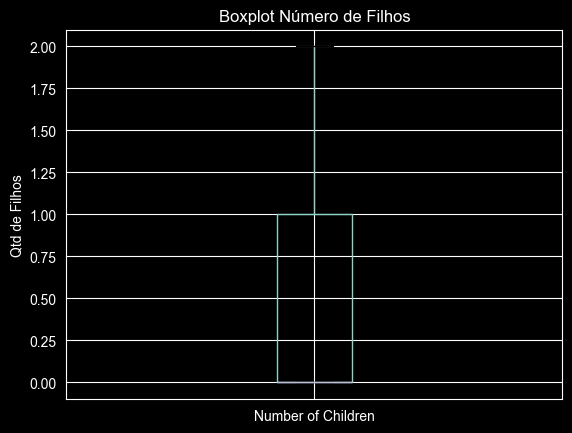

In [18]:
df.boxplot(column='Number of Children')
plt.title('Boxplot Número de Filhos')
plt.ylabel('Qtd de Filhos')
plt.show()

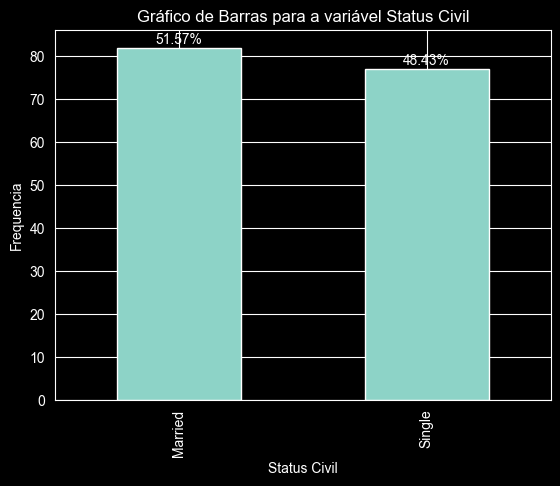

In [19]:
contagem = df['Marital Status'].value_counts()
porcentagem = (contagem/contagem.sum()) * 100

ax = contagem.plot(kind='bar')

for i, v in enumerate(contagem):
    ax.text(i, v+1, f'{porcentagem.iloc[i]:.2f}%', ha='center')
    
plt.title('Gráfico de Barras para a variável Status Civil')
plt.xlabel('Status Civil')
plt.ylabel('Frequencia')

plt.show()


Agora já temos os outliers de 'Number of Children' removidos

# Insights

A distribuição de renda anual e de idade aparentam uma distribuição normal. Bem diferente do número de Filhos que mostra uma tendência em ter mais filhos nos registros. A analise de Status Cicil também apresenta uma distribuição equilibrada. Como a categoria 'Age' apresenta uma boa distribuição, os dados faltantes serão substituídos pela média de 'Age' para não perdermos os 20% dos registros.

In [20]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [21]:
df.isnull().sum()

Age                   0
Gender                0
Income                0
Education             0
Marital Status        0
Number of Children    0
Home Ownership        0
Credit Score          0
dtype: int64

**D) Realize a análise Bivariada.
Tente responder as seguintes perguntas com gráficos seguidos de insights:**



*   Existe relação entre a idade e o status civil?
*   Qual a relação entre o score de crédito e o nível de escolaridade?
*  O salário parece influenciar na idade?
* O salário parece influenciar no Score de Crédito?
* Clientes com casa própria tendem a ter um score mais alto?



In [22]:
#seu código aqui
# Análise 1

#Calcular a porcentagem de cada categoria por status civil

df_grouped = df.groupby(['Age', 'Marital Status']).size().reset_index(name='count')
total_por_status = df_grouped.groupby('Marital Status')['count'].transform('sum')
df_grouped['percent'] = (df_grouped['count'] / total_por_status) * 100

# Cria gráfico de baras empilhadas

fig = px.bar(df_grouped, x='Marital Status', y='percent', color='Age', barmode='stack',
            labels={'Age': 'Age', 'percent': 'Porcentagem', 'Marital Status': 'Status Civil'})

fig.update_layout(title='Relação entre Idade e Status Civil',
                  yaxis_title='Porcentagem',
                  legend_title='Idade')

fig.show()

## Insight 1

A Maioria das pessoas casadas possuem idade acima dos 45 anos. Os mais novos são solteiros 

In [23]:
# Análise 2

#Calcular a porcentagem de cada categoria por credit score

df_grouped = df.groupby(['Credit Score', 'Education']).size().reset_index(name='count')
total_por_credit = df_grouped.groupby('Credit Score')['count'].transform('sum')
df_grouped['percent'] = (df_grouped['count'] / total_por_credit) * 100

# Cria gráfico de baras empilhadas

fig = px.bar(df_grouped, x='Credit Score', y='percent', color='Education', barmode='stack',
            labels={'Education': 'educação', 'percent': 'Porcentagem', 'Credit Score': 'Pontuação de Crédito'})

fig.update_layout(title='Relação entre Pontuação de Credito e Educação',
                  yaxis_title='Porcentagem',
                  legend_title='Pontuação de Crédito')

fig.show()

## Insight 2

Aqui se mostra bem nítido que pessoas com formações básicas possuem baixa pontuação de crédito. Enquanto Doutores e Mestres possuem alta pontuação.

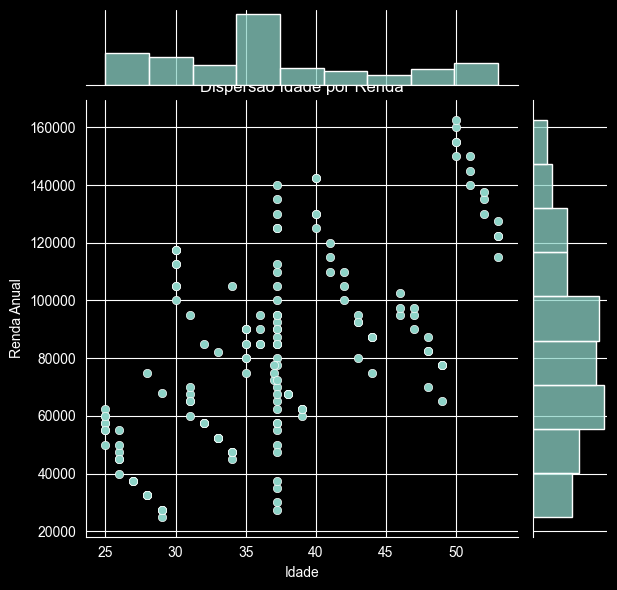

In [24]:
# Análise 3 - Salário e Idade

sns.jointplot(x='Age', y='Income', data=df, kind='scatter')
plt.title('Dispersão Idade por Renda')
plt.xlabel('Idade')
plt.ylabel('Renda Anual')
plt.show()

## Insight 3

Há sim uma correlação da Idade com a Renda Anual. É possível ver que as idades mais avançadas possuem uma renda anual maior

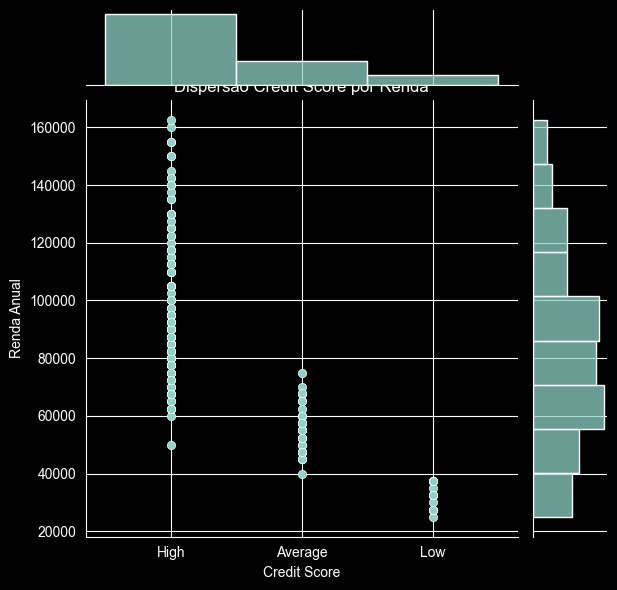

In [25]:
# Análise 4 - Salário e Credit Score

sns.jointplot(x='Credit Score', y='Income', data=df, kind='scatter')
plt.title('Dispersão Credit Score por Renda')
plt.xlabel('Credit Score')
plt.ylabel('Renda Anual')
plt.show()

## Insight 4

Clientes com maiores salários possuem mais score

In [26]:
# Análise 5 - Clientes com Casa Própria tendem a ter um credit score mais alto?

#Calcular a porcentagem de cada categoria por credit score

df_grouped = df.groupby(['Credit Score', 'Home Ownership']).size().reset_index(name='count')
total_por_credit = df_grouped.groupby('Home Ownership')['count'].transform('sum')
df_grouped['percent'] = (df_grouped['count'] / total_por_credit) * 100

# Cria gráfico de baras empilhadas

fig = px.bar(df_grouped, x='Home Ownership', y='percent', color='Credit Score', barmode='stack',
            labels={'Home Ownership': 'Casa Própria', 'percent': 'Porcentagem', 'Credit Score': 'Pontuação de Crédito'})

fig.update_layout(title='Relação entre Pontuação de Credito e Casa Prória',
                  yaxis_title='Porcentagem',
                  legend_title='Pontuação de Crédito')

fig.show()

## Insight 5

Existe um fortíssimo indicativo que pessoa com casa própria possuem pontuação alta de crédito. Por volta de um pouco mais de 98%

**E) Que outras perguntas te parecem fazer sentido explorarmos a resposta para conhecermos mais nossa base de dados e o comportamento dos clientes?**

 Elabore mais 3 perguntas e responda utilizando gráficos + insights.

In [27]:
# seu código aqui
# Pergunta 1 - Existe realação do gênero com o Credit Score?

#Calcular a porcentagem de cada categoria por credit score

df_grouped = df.groupby(['Credit Score', 'Gender']).size().reset_index(name='count')
total_por_credit = df_grouped.groupby('Gender')['count'].transform('sum')
df_grouped['percent'] = (df_grouped['count'] / total_por_credit) * 100

# Cria gráfico de baras empilhadas

fig = px.bar(df_grouped, x='Gender', y='percent', color='Credit Score', barmode='stack',
            labels={'Gender': 'Gênero', 'percent': 'Porcentagem', 'Credit Score': 'Pontuação de Crédito'})

fig.update_layout(title='Relação entre Pontuação de Credito e Gênero',
                  yaxis_title='Porcentagem',
                  legend_title='Pontuação de Crédito')

fig.show()


## Insight 1

Homens não possuem pontuação baixa de crédito, apenas média e alta

In [28]:
# seu código aqui
# Pergunta 2 - Existe realação da quantidade de filhos com o Credit Score?

#Calcular a porcentagem de cada categoria por credit score

df_grouped = df.groupby(['Credit Score', 'Number of Children']).size().reset_index(name='count')
total_por_credit = df_grouped.groupby('Credit Score')['count'].transform('sum')
df_grouped['percent'] = (df_grouped['count'] / total_por_credit) * 100

# Cria gráfico de baras empilhadas

fig = px.bar(df_grouped, x='Credit Score', y='percent', color='Number of Children', barmode='stack',
            labels={'Number of Children': 'Número de Filhos', 'percent': 'Porcentagem', 'Credit Score': 'Pontuação de Crédito'})

fig.update_layout(title='Relação entre Pontuação de Credito e Número de Filhos',
                  yaxis_title='Porcentagem',
                  legend_title='Pontuação de Crédito')

fig.show()


## Insight 2

Pessoas que não possuem filhos possuem baixa pontuação de crédito

In [29]:
# seu código aqui
# Pergunta 3 - Existe realação do status civil com o Credit Score?

#Calcular a porcentagem de cada categoria por credit score

df_grouped = df.groupby(['Credit Score', 'Marital Status']).size().reset_index(name='count')
total_por_credit = df_grouped.groupby('Marital Status')['count'].transform('sum')
df_grouped['percent'] = (df_grouped['count'] / total_por_credit) * 100

# Cria gráfico de baras empilhadas

fig = px.bar(df_grouped, x='Marital Status', y='percent', color='Credit Score', barmode='stack',
            labels={'Marital Status': 'Status Civil', 'percent': 'Porcentagem', 'Credit Score': 'Pontuação de Crédito'})

fig.update_layout(title='Relação entre Pontuação de Credito e status civil',
                  yaxis_title='Porcentagem',
                  legend_title='Pontuação de Crédito')

fig.show()


## Insight 3

Quase todas as pessoas casadas possuem um score de crédito alto

# Etapa 3: Relize os passos que vimos no módulo 17, de Correlação, Balanceamento, atributos categóricos e divisão base treino e teste.

**A) Vamos começar pela análise de correlação, plote da forma que achar melhor a análise de correlação, seja pela tabela ou pelo gráfico da matriz.**

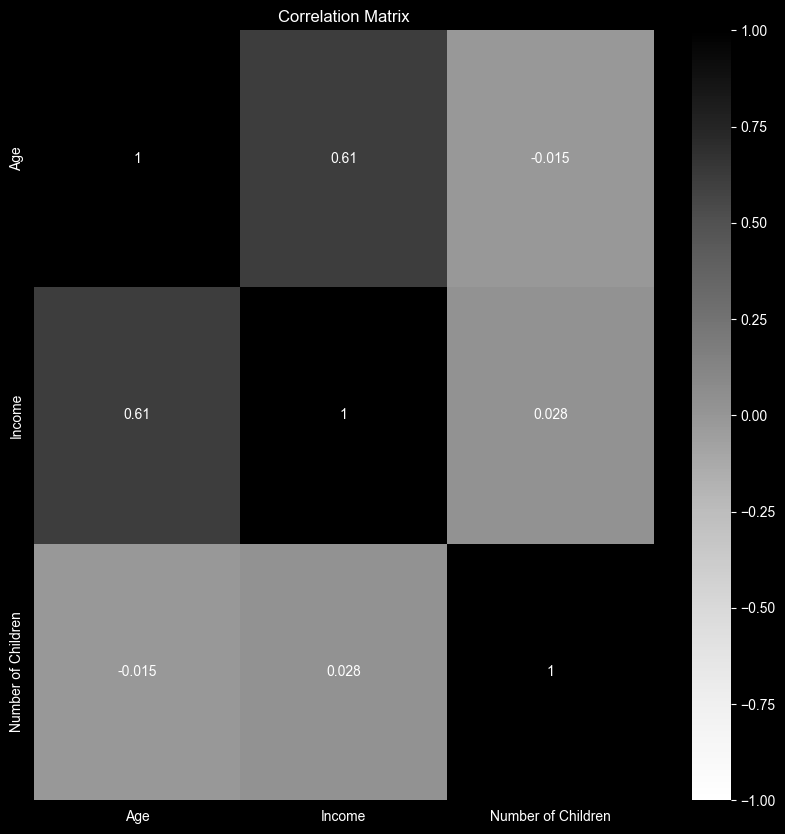

In [30]:
#seu código aqui

correlation_matrix = df.select_dtypes(include=['number']).corr()

# PLotar o mapa de calor da matriz de correlação

plt.figure(figsize=(10,10))
sns.heatmap(correlation_matrix,annot=True, cmap='Greys',
            vmin=-1, vmax=1, annot_kws={'size': 10})
plt.title('Correlation Matrix')
plt.show()

**B) Você encontrou variáveis que tem uma média ou alta correlação? Se sim, quais? Te parece fazer sentido essas variáveis terem alta correlação? Justifique.**

# Justificativa

Sim! As variáveis 'Income' e 'Age' possuem alta correlação

**C) Temos muitos atributos categóricos nessa base, não? Vamos realizar a o tratamento desses atributos utilizando Label Encoder ou one hot. Após, exclua as colunas categóricas.**

In [31]:
#seu código aqui
# Será utilizado o Label Encoder

label_encoder = LabelEncoder()

df['Education_encoded'] = label_encoder.fit_transform(df['Education'])
df['Credit Score'] = label_encoder.fit_transform(df['Credit Score'])

df = pd.get_dummies(df, columns = ['Marital Status'], prefix='Marital Status', drop_first=True)
df = pd.get_dummies(df, columns = ['Home Ownership'], prefix='Home Ownership', drop_first=True)
df = pd.get_dummies(df, columns = ['Gender'], prefix='Gender', drop_first=True)




In [32]:
df.head(10)

,Age,Income,Education,Number of Children,Credit Score,Education_encoded,Marital Status_Single,Home Ownership_Rented,Gender_Male
0,25.000,50000.0,Bachelor's Degree,0,1,1,True,True,False
1,30.000,100000.0,Master's Degree,2,1,4,False,False,True
2,35.000,75000.0,Doctorate,1,1,2,False,False,False
3,40.000,125000.0,High School Diploma,0,1,3,True,False,True
5,50.000,150000.0,Master's Degree,0,1,4,False,False,True
6,26.000,40000.0,Associate's Degree,0,0,0,True,True,False
7,31.000,60000.0,Bachelor's Degree,0,0,1,True,True,True
8,37.208,80000.0,Master's Degree,2,1,4,False,False,False
9,37.208,105000.0,Doctorate,0,1,2,True,False,True
10,37.208,90000.0,High School Diploma,1,1,3,False,False,False


In [33]:
df = df.drop('Education', axis=1)

**D) Vamos plotar novamente a correlação, agora observando com as variáveis categóricas. Identifique se temos novas variáveis com forte correlação.**

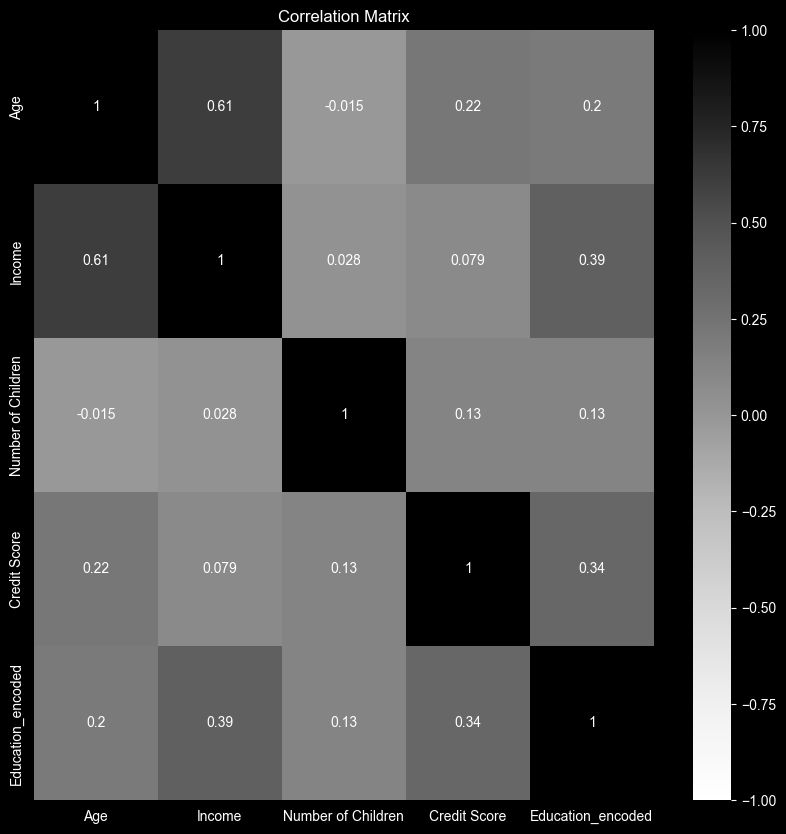

In [34]:
#seu código aqui
correlation_matrix = df.select_dtypes(include=['number']).corr()

# PLotar o mapa de calor da matriz de correlação

plt.figure(figsize=(10,10))
sns.heatmap(correlation_matrix,annot=True, cmap='Greys',
            vmin=-1, vmax=1, annot_kws={'size': 10})
plt.title('Correlation Matrix')
plt.show()

## Insight

Temos uma forte correlação do nível de edcuação com a Renda e Score de crédito

**F) Faça a separação da base em treino e teste e verifique utilizando shape:**

In [35]:
#seu código aqui
X = df.drop('Credit Score', axis=1)
Y = df['Credit Score']

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
# Separar os dados em conjunto de treino e teste
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

In [38]:
print('Tamanho de X_train:', X_train.shape)

Tamanho de X_train: (119, 7)


In [39]:
print('Tamanho de X_test:', X_test.shape)

Tamanho de X_test: (40, 7)


In [40]:
print('Tamanho de Y_train:', Y_train.shape)

Tamanho de Y_train: (119,)


In [41]:
print('Tamanho de Y_test:', Y_test.shape)

Tamanho de Y_test: (40,)


**G) É hora de verificar se nossa coluna de Score de crédito está balanceada, verifique através de um gráfico e traga sua opinião acerca do balanceamento.**

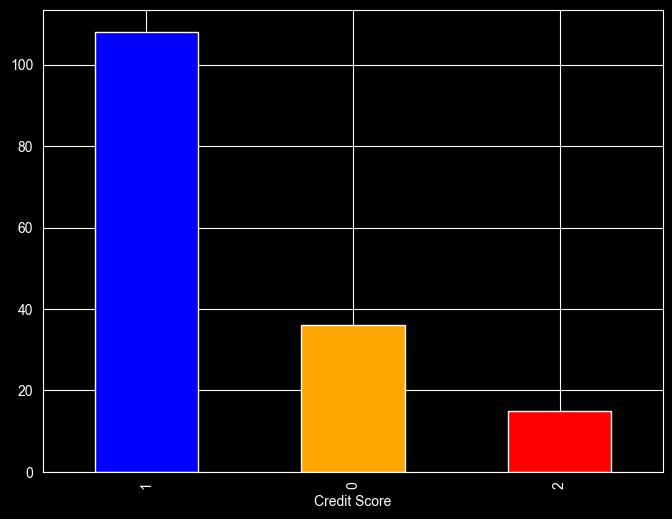

In [42]:
#seu código aqui
credit_counts = df['Credit Score'].value_counts()
plt.figure(figsize=(8,6))
credit_counts.plot(kind='bar', color=['blue', 'orange', 'red'])
plt.show()

In [43]:
print((df['Credit Score'].value_counts(normalize=True)*100))

Credit Score
1    67.924528
0    22.641509
2     9.433962
Name: proportion, dtype: float64


**H) Vamos realizar o balancecamento dos dados da coluna de credit score.**
Se lembre que realizazmos apenas para a base de treino.

In [44]:
#seu código aqui
from imblearn.over_sampling import SMOTE

# Criando uma instância do SMOTE
smote = SMOTE(random_state=42)

# Aplicando o SMOTE aos dados de treinamento
X_train_balanced, Y_train_balanced = smote.fit_resample(X_train, Y_train)

# Verificando a distribuição das classes após o balanceamnto
print('Distribuição das classes após o balanceamento:')
print(Y_train_balanced.value_counts())

Distribuição das classes após o balanceamento:
Credit Score
1    81
0    81
2    81
Name: count, dtype: int64


In [45]:
Y_train_balanced.to_csv('../data/processed/y_train_balanced.csv', index=False)

In [46]:
X_train_balanced.to_csv('../data/processed/X_train_balanced.csv', index=False)

In [47]:
Y_test.to_csv('../data/processed/y_test.csv', index=False)

In [48]:
X_test.to_csv('../data/processed/X_test.csv', index=False)